# Chapter 6: Distributions and Grids of Values

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 6.1 Histograms

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders.csv')
orders.head()

,order_id,weekday,hour,region,order_value,delivery_days
0,1001,Thu,20,East,88,7
1,1002,Wed,15,East,93,4
2,1003,Wed,18,South,246,6
3,1004,Wed,20,West,259,6
4,1005,Sun,14,East,165,4


### `ax.hist()`

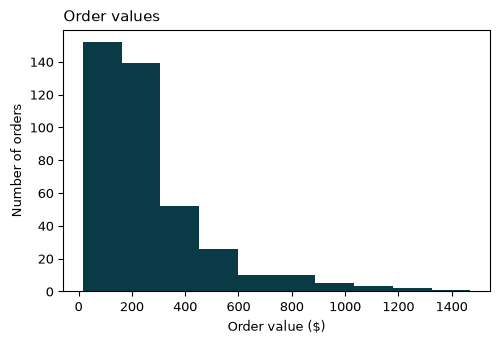

In [3]:
fig, ax = plt.subplots()
ax.hist(orders['order_value'])
ax.set_title('Order values')
ax.set_xlabel('Order value ($)')
ax.set_ylabel('Number of orders')
plt.show()

In [4]:
orders['order_value'].describe()

count     400.000000
mean      264.030000
std       223.621826
min        16.000000
25%       118.000000
50%       191.000000
75%       336.500000
max      1470.000000
Name: order_value, dtype: float64

### `bins=`

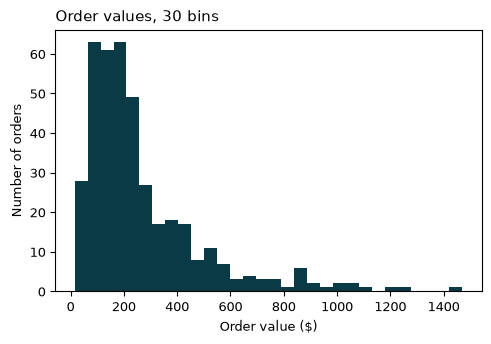

In [5]:
fig, ax = plt.subplots()
ax.hist(orders['order_value'], bins=30)
ax.set_title('Order values, 30 bins')
ax.set_xlabel('Order value ($)')
ax.set_ylabel('Number of orders')
plt.show()

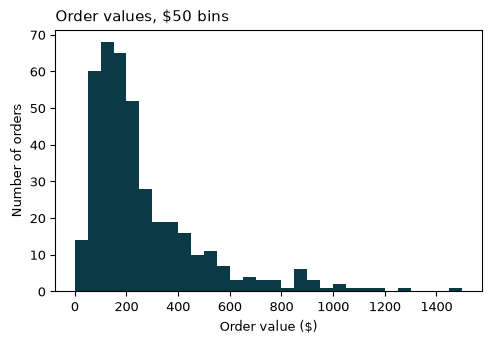

In [6]:
fig, ax = plt.subplots()
ax.hist(orders['order_value'], bins=np.arange(0, 1550, 50))
ax.set_title('Order values, $50 bins')
ax.set_xlabel('Order value ($)')
ax.set_ylabel('Number of orders')
plt.show()

### `cumulative=True`

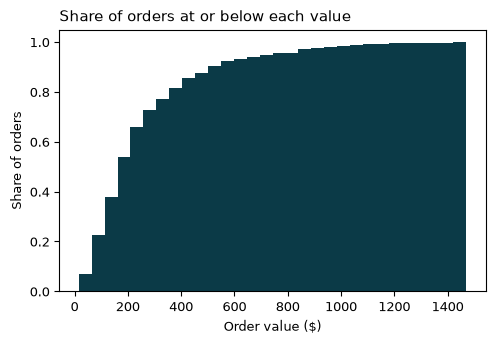

In [7]:
fig, ax = plt.subplots()
ax.hist(orders['order_value'], bins=30, density=True,
        cumulative=True)
ax.set_title('Share of orders at or below each value')
ax.set_xlabel('Order value ($)')
ax.set_ylabel('Share of orders')
plt.show()

### `df.plot.hist()`

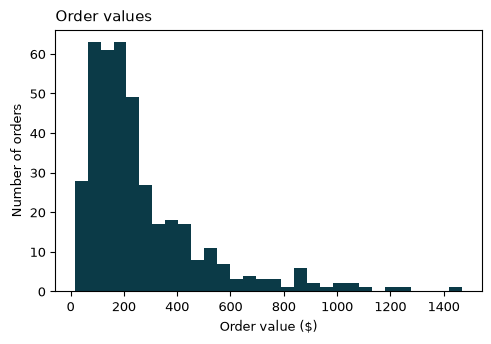

In [8]:
ax = orders['order_value'].plot.hist(bins=30)
ax.set_title('Order values')
ax.set_xlabel('Order value ($)')
ax.set_ylabel('Number of orders')
plt.show()

In [9]:
delivery = orders.pivot(columns='region', values='delivery_days')
delivery.head()

region,East,North,South,West
0,7.0,NaN,NaN,NaN
1,4.0,NaN,NaN,NaN
2,NaN,NaN,6.0,NaN
3,NaN,NaN,NaN,6.0
4,4.0,NaN,NaN,NaN


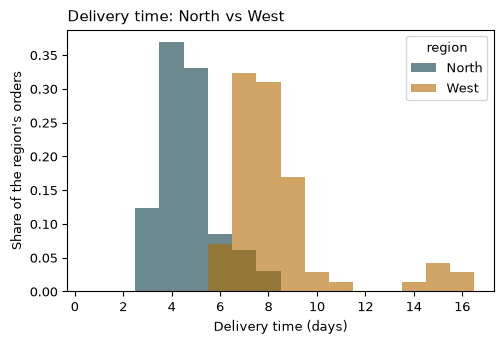

In [10]:
ax = delivery[['North', 'West']].plot.hist(
    bins=np.arange(0.5, 17), alpha=0.6, density=True)
ax.set_title('Delivery time: North vs West')
ax.set_xlabel('Delivery time (days)')
ax.set_ylabel("Share of the region's orders")
plt.show()

## 6.2 Box Plots

### `ax.boxplot()`

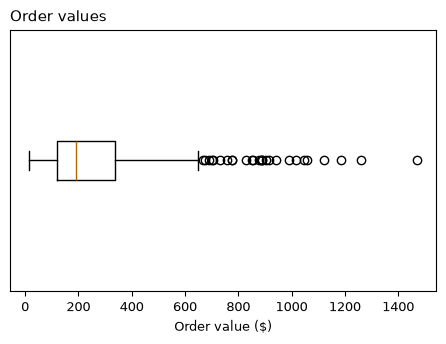

In [11]:
fig, ax = plt.subplots()
ax.boxplot(orders['order_value'], orientation='horizontal')
ax.set_yticks([])
ax.set_title('Order values')
ax.set_xlabel('Order value ($)')
plt.show()

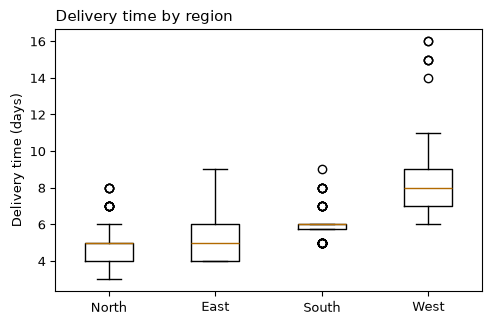

In [12]:
regions = ['North', 'East', 'South', 'West']
groups = [orders.loc[orders['region'] == r, 'delivery_days']
          for r in regions]

fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=regions)
ax.set_title('Delivery time by region')
ax.set_ylabel('Delivery time (days)')
plt.show()

Shown in the book but not run here:

```python
groups = []
for r in regions:
    groups.append(orders.loc[orders['region'] == r, 'delivery_days'])
```

### `df.plot.box()`

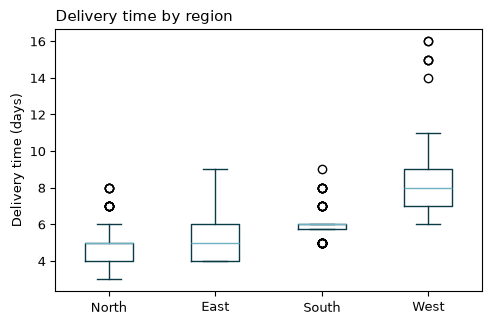

In [13]:
ax = delivery[regions].plot.box()
ax.set_title('Delivery time by region')
ax.set_ylabel('Delivery time (days)')
plt.show()

### Showing the mean and the outliers

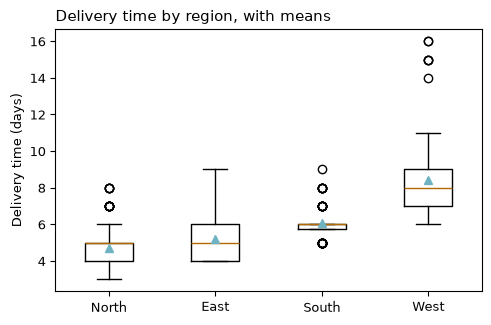

In [14]:
fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=regions, showmeans=True)
ax.set_title('Delivery time by region, with means')
ax.set_ylabel('Delivery time (days)')
plt.show()

## 6.3 Grids of Values with imshow

### Building the grid with `df.pivot_table()`

In [15]:
grid = orders.pivot_table(index='weekday', columns='hour',
                          values='order_id', aggfunc='count',
                          fill_value=0)
grid

hour,9,10,11,12,13,14,15,16,17,18,19,20,21,22
weekday,,,,,,,,,,,,,,
Fri,0,2,3,9,12,5,4,0,0,1,6,10,6,6
Mon,1,1,2,5,7,6,4,1,2,3,4,15,3,4
Sat,0,1,4,9,12,11,6,2,0,3,4,11,9,6
Sun,1,0,1,8,13,4,2,0,0,0,7,5,5,5
Thu,0,2,3,4,4,4,2,1,1,2,5,11,5,5
Tue,2,0,3,9,5,9,1,0,0,2,3,12,7,2
Wed,0,1,1,4,8,3,1,0,0,7,4,12,1,3


In [16]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
grid = grid.loc[days]
grid.iloc[:, :6]

hour,9,10,11,12,13,14
weekday,,,,,,
Mon,1,1,2,5,7,6
Tue,2,0,3,9,5,9
Wed,0,1,1,4,8,3
Thu,0,2,3,4,4,4
Fri,0,2,3,9,12,5
Sat,0,1,4,9,12,11
Sun,1,0,1,8,13,4


### `ax.imshow()`

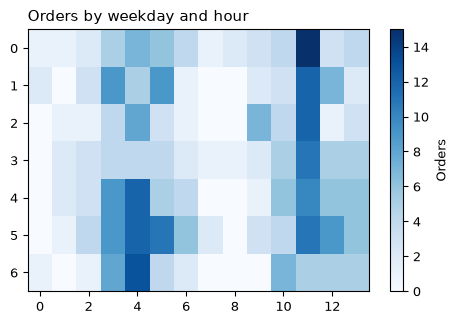

In [17]:
fig, ax = plt.subplots()
im = ax.imshow(grid.values, cmap='Blues', aspect='auto')
fig.colorbar(im, label='Orders')
ax.set_title('Orders by weekday and hour')
plt.show()

### Labeling rows and columns

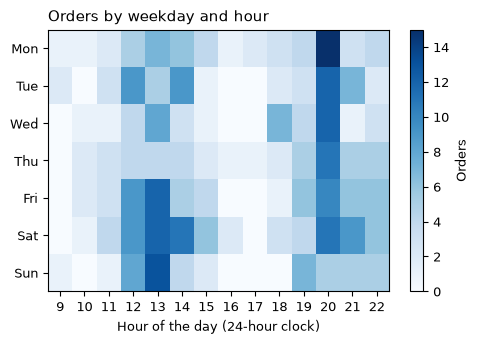

In [18]:
fig, ax = plt.subplots()
im = ax.imshow(grid.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
fig.colorbar(im, label='Orders')
ax.set_title('Orders by weekday and hour')
ax.set_xlabel('Hour of the day (24-hour clock)')
plt.show()

### Choosing a colormap

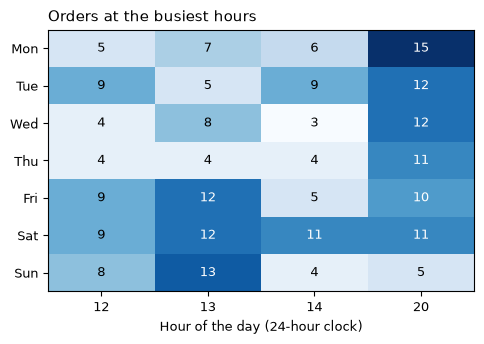

In [19]:
busy = grid[[12, 13, 14, 20]]  # hours, not positions

fig, ax = plt.subplots()
im = ax.imshow(busy.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(busy.columns)), busy.columns)
ax.set_yticks(range(len(busy.index)), busy.index)
for row in range(len(busy.index)):
    for col in range(len(busy.columns)):
        value = busy.iloc[row, col]
        ink = 'black'
        if value > busy.values.max() * 0.6:
            ink = 'white'
        ax.text(col, row, value, ha='center', va='center',
                color=ink)
ax.set_title('Orders at the busiest hours')
ax.set_xlabel('Hour of the day (24-hour clock)')
plt.show()